# Lab 2 – Spam Classification with Naive Bayes & Airbnb NYC Price Outliers

**Name:** Juan Antonio Sainz Gálvez  
**Student ID:** 9072844  
**Course:** CSCN8000 – AI Algorithms Math (AAIML), Conestoga College  
**Date:** October 2026

This lab has two parts:

- **Part A – Probability:** classify emails as *spam* or *not spam (ham)* with two Naive Bayes classifiers (Gaussian and Multinomial), compare them, and use the best model to predict on test emails.
- **Part B – Statistics:** remove outliers from the Airbnb New York City 2019 dataset based on the **price per night**, comparing techniques built on measures of central tendency (mean, median) and dispersion (standard deviation, IQR, percentiles, MAD), and produce a clean dataset.

Both datasets come from the course repository (`practical_labs/`).

## 1. Imports and settings

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.naive_bayes import GaussianNB, MultinomialNB
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, classification_report)

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)
pd.set_option("display.max_colwidth", 120)

DATA_DIR = "../../practical_labs/"   # datasets provided in the course repo
RANDOM_STATE = 42

# Part A – Spam vs Not Spam with Naive Bayes

## 2. Load and inspect the dataset

In [2]:
spam_df = pd.read_csv(DATA_DIR + "Lab2_dataset.csv")
print("Shape (rows, columns):", spam_df.shape)
spam_df.head()

Shape (rows, columns): (5171, 4)


,Unnamed: 0,label,text,label_num
0,605,ham,"Subject: enron methanol ; meter # : 988291\nthis is a follow up to the note i gave you on monday , 4 / 3 / 00 { prel...",0
1,2349,ham,"Subject: hpl nom for january 9 , 2001\n( see attached file : hplnol 09 . xls )\n- hplnol 09 . xls",0
2,3624,ham,"Subject: neon retreat\nho ho ho , we ' re around to that most wonderful time of the year - - - neon leaders retreat ...",0
3,4685,spam,"Subject: photoshop , windows , office . cheap . main trending\nabasements darer prudently fortuitous undergone\nligh...",1
4,2030,ham,Subject: re : indian springs\nthis deal is to book the teco pvr revenue . it is my understanding that teco\njust sen...,0


In [3]:
spam_df = spam_df.drop(columns=["Unnamed: 0"])   # old index column, not a feature
print("Missing values per column:\n", spam_df.isna().sum(), sep="")
print("\nClass counts:\n", spam_df["label"].value_counts(), sep="")
print("\nClass proportions:\n", spam_df["label"].value_counts(normalize=True).round(3), sep="")

Missing values per column:
label        0
text         0
label_num    0
dtype: int64

Class counts:
label
ham     3672
spam    1499
Name: count, dtype: int64

Class proportions:
label
ham     0.71
spam    0.29
Name: proportion, dtype: float64


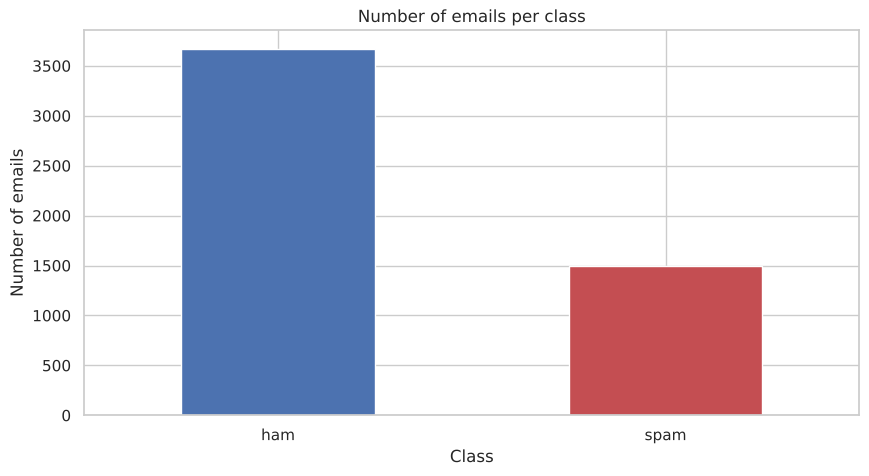

In [4]:
ax = spam_df["label"].value_counts().plot(kind="bar", color=["#4C72B0", "#C44E52"])
ax.set_title("Number of emails per class")
ax.set_xlabel("Class")
ax.set_ylabel("Number of emails")
plt.xticks(rotation=0)
plt.show()

The dataset has **5,171 emails** with three useful columns: `text` (the email), `label` (`ham`/`spam`) and `label_num` (0 = ham, 1 = spam). About **71% are ham and 29% are spam**, so the classes are imbalanced – that is why we look at precision, recall and F1, not only accuracy.

In [5]:
dups = spam_df["text"].duplicated().sum()
print("Duplicated email texts:", dups)
spam_df = spam_df.drop_duplicates(subset="text").reset_index(drop=True)
print("Shape after removing duplicates:", spam_df.shape)

Duplicated email texts: 178
Shape after removing duplicates: (4993, 3)


Duplicated emails are removed **before** splitting so the same email cannot appear in both train and test (that would inflate the test score).

## 3. Train / test split

80% train, 20% test. `stratify` keeps the same spam/ham proportion in both sets, and `random_state` makes the result reproducible.

In [6]:
X_text = spam_df["text"]
y = spam_df["label_num"]

X_train_text, X_test_text, y_train, y_test = train_test_split(
    X_text, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)

print("Train emails:", len(X_train_text), " | spam share:", round(y_train.mean(), 3))
print("Test emails: ", len(X_test_text), " | spam share:", round(y_test.mean(), 3))

Train emails: 3994  | spam share: 0.293
Test emails:  999  | spam share: 0.293


## 4. From text to numbers (bag of words)

Naive Bayes works with numbers, so each email is converted into a vector of **word counts** with `CountVectorizer`:

- the vocabulary is learned **only from the training emails** (no information from the test set leaks in);
- English stop words (*the, and, is…*) are removed;
- the **full vocabulary** is kept (no word limit), so both models see exactly the same features.

In [7]:
vectorizer = CountVectorizer(stop_words="english")
X_train = vectorizer.fit_transform(X_train_text)
X_test = vectorizer.transform(X_test_text)

print("Train matrix (emails x words):", X_train.shape)
print("Test matrix  (emails x words):", X_test.shape)
print("Example words in the vocabulary:", list(vectorizer.get_feature_names_out()[10000:10015]))

Train matrix (emails x words): (3994, 43738)
Test matrix  (emails x words): (999, 43738)
Example words in the vocabulary: ['carries', 'carrington', 'carrion', 'carrizo', 'carroll', 'carrot', 'carrtwheel', 'carry', 'carrying', 'carryingcase', 'carrylevery', 'carryn', 'carryover', 'cars', 'carson']


## 5. How each Naive Bayes model uses probability

Both models apply **Bayes' theorem** with the "naive" assumption that words are independent given the class:

$$P(\text{spam} \mid \text{email}) \propto P(\text{spam}) \prod_i P(\text{word}_i \mid \text{spam})$$

The difference is how they model $P(\text{word}_i \mid \text{class})$:

| Model | Assumption about each feature | Fit for word counts? |
|---|---|---|
| **GaussianNB** | Each word count follows a **normal (bell-shaped) distribution** inside each class, described by its mean and variance | Weak – counts are discrete, mostly zeros and never negative |
| **MultinomialNB** | Word counts follow a **multinomial distribution** (how often each word is drawn from the class vocabulary) | Strong – designed for word counts |

## 6. Train the Gaussian Naive Bayes model

In [8]:
# GaussianNB needs a dense array; float32 halves the memory (~0.7 GB for the train matrix)
gnb = GaussianNB()
gnb.fit(X_train.toarray().astype(np.float32), y_train)
y_pred_gnb = gnb.predict(X_test.toarray().astype(np.float32))

print(classification_report(y_test, y_pred_gnb, target_names=["ham", "spam"], digits=4))

              precision    recall  f1-score   support

         ham     0.9545    0.9802    0.9672       706
        spam     0.9489    0.8874    0.9171       293

    accuracy                         0.9530       999
   macro avg     0.9517    0.9338    0.9421       999
weighted avg     0.9528    0.9530    0.9525       999



## 7. Train the Multinomial Naive Bayes model

In [9]:
mnb = MultinomialNB()                          # alpha=1.0 (Laplace smoothing) by default
mnb.fit(X_train, y_train)
y_pred_mnb = mnb.predict(X_test)

print(classification_report(y_test, y_pred_mnb, target_names=["ham", "spam"], digits=4))

              precision    recall  f1-score   support

         ham     0.9815    0.9773    0.9794       706
        spam     0.9459    0.9556    0.9508       293

    accuracy                         0.9710       999
   macro avg     0.9637    0.9665    0.9651       999
weighted avg     0.9711    0.9710    0.9710       999



## 8. Which model performs better?

In [10]:
def metrics_row(name, y_true, y_pred):
    return {"Model": name,
            "Accuracy": accuracy_score(y_true, y_pred),
            "Precision (spam)": precision_score(y_true, y_pred),
            "Recall (spam)": recall_score(y_true, y_pred),
            "F1 (spam)": f1_score(y_true, y_pred)}

results_a = pd.DataFrame([metrics_row("GaussianNB", y_test, y_pred_gnb),
                          metrics_row("MultinomialNB", y_test, y_pred_mnb)]).set_index("Model")
results_a.round(4)

,Accuracy,Precision (spam),Recall (spam),F1 (spam)
Model,,,,
GaussianNB,0.953,0.9489,0.8874,0.9171
MultinomialNB,0.971,0.9459,0.9556,0.9508


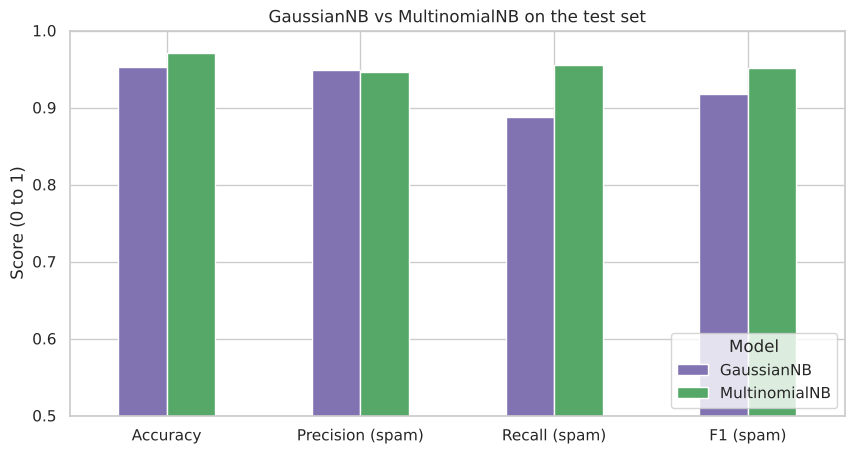

In [11]:
ax = results_a.T.plot(kind="bar", color=["#8172B2", "#55A868"])
ax.set_title("GaussianNB vs MultinomialNB on the test set")
ax.set_ylabel("Score (0 to 1)")
ax.set_ylim(0.5, 1.0)
plt.xticks(rotation=0)
plt.legend(title="Model", loc="lower right")
plt.show()

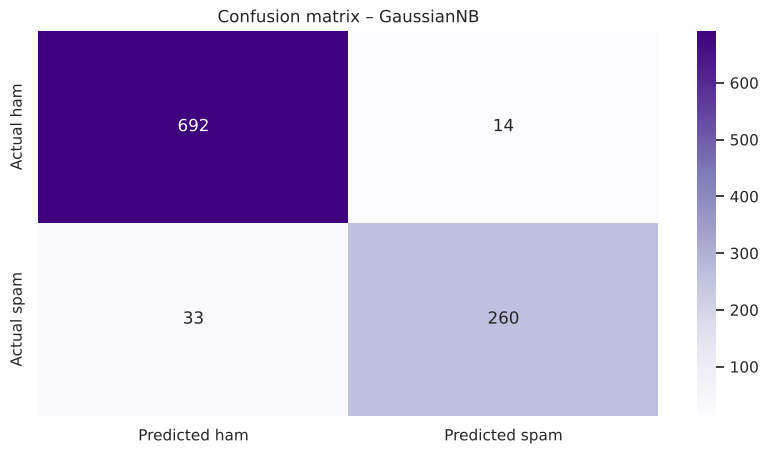

In [12]:
cm_gnb = confusion_matrix(y_test, y_pred_gnb)
sns.heatmap(cm_gnb, annot=True, fmt="d", cmap="Purples",
            xticklabels=["Predicted ham", "Predicted spam"],
            yticklabels=["Actual ham", "Actual spam"])
plt.title("Confusion matrix – GaussianNB")
plt.show()

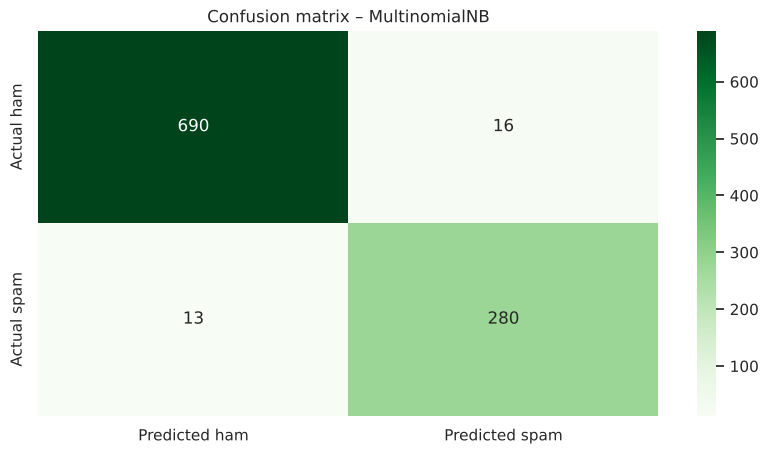

In [13]:
cm_mnb = confusion_matrix(y_test, y_pred_mnb)
sns.heatmap(cm_mnb, annot=True, fmt="d", cmap="Greens",
            xticklabels=["Predicted ham", "Predicted spam"],
            yticklabels=["Actual ham", "Actual spam"])
plt.title("Confusion matrix – MultinomialNB")
plt.show()

In [14]:
for name, cm in [("GaussianNB", cm_gnb), ("MultinomialNB", cm_mnb)]:
    tn, fp, fn, tp = cm.ravel()
    print(f"{name}: {fp} ham emails wrongly sent to spam (false positives), "
          f"{fn} spam emails that got through (false negatives)")

best_name = results_a["F1 (spam)"].idxmax()
print(f"\nBest model by F1 on spam: {best_name}")

GaussianNB: 14 ham emails wrongly sent to spam (false positives), 33 spam emails that got through (false negatives)
MultinomialNB: 16 ham emails wrongly sent to spam (false positives), 13 spam emails that got through (false negatives)

Best model by F1 on spam: MultinomialNB


**Result:** with the full vocabulary, **MultinomialNB performs better** – higher accuracy, recall and F1. Both models send a similar number of legitimate emails to spam (precision is almost the same), but MultinomialNB **lets far fewer spam emails through** (higher recall). This matches the theory in section 5: word counts are discrete and full of zeros, which is exactly what the multinomial distribution models, while GaussianNB forces a bell curve onto each word.

### 8.1 Does the size of the vocabulary change the winner?

While building the lab I first limited the vocabulary to 3,000 words and, surprisingly, GaussianNB came out slightly ahead. So here both models are compared on the **same split** with different vocabulary sizes.

In [15]:
rows = []
for size in [1000, 3000, 5000, None]:
    v = CountVectorizer(stop_words="english", max_features=size)
    A, B = v.fit_transform(X_train_text), v.transform(X_test_text)
    g_pred = GaussianNB().fit(A.toarray().astype(np.float32), y_train).predict(B.toarray().astype(np.float32))
    m_pred = MultinomialNB().fit(A, y_train).predict(B)
    rows.append({"Vocabulary size": f"{A.shape[1]:,}" + (" (full)" if size is None else ""),
                 "GaussianNB accuracy": round(accuracy_score(y_test, g_pred), 4),
                 "MultinomialNB accuracy": round(accuracy_score(y_test, m_pred), 4),
                 "GaussianNB F1 (spam)": round(f1_score(y_test, g_pred), 4),
                 "MultinomialNB F1 (spam)": round(f1_score(y_test, m_pred), 4)})
vocab_results = pd.DataFrame(rows).set_index("Vocabulary size")
vocab_results

,GaussianNB accuracy,MultinomialNB accuracy,GaussianNB F1 (spam),MultinomialNB F1 (spam)
Vocabulary size,,,,
"1,000",0.9369,0.9349,0.9008,0.8957
"3,000",0.9520,0.9489,0.9216,0.9171
"5,000",0.9720,0.9520,0.9527,0.9216
"43,738 (full)",0.9530,0.9710,0.9171,0.9508


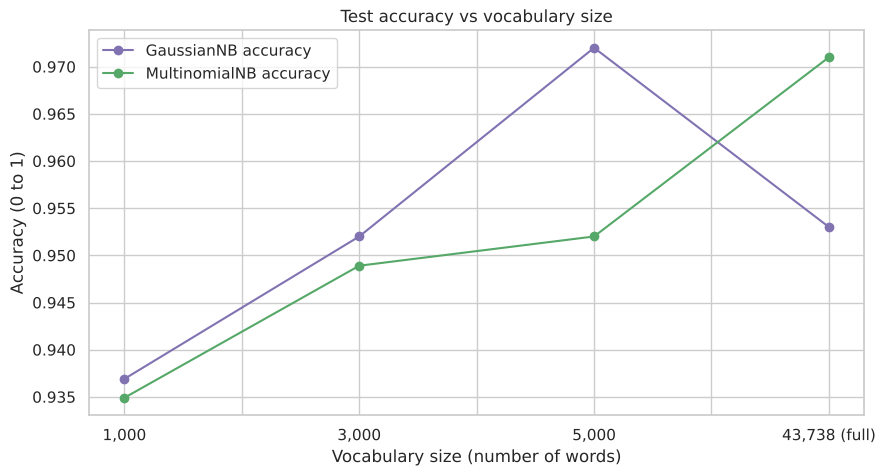

In [16]:
ax = vocab_results[["GaussianNB accuracy", "MultinomialNB accuracy"]].plot(
    marker="o", color=["#8172B2", "#55A868"])
ax.set_title("Test accuracy vs vocabulary size")
ax.set_xlabel("Vocabulary size (number of words)")
ax.set_ylabel("Accuracy (0 to 1)")
plt.show()

**Interpretation:** with a small vocabulary only the most frequent words remain; they appear in many emails and their counts behave a bit more like continuous values, so GaussianNB copes and can even edge ahead. As more (rarer) words are added, most counts are zero, which breaks the bell-curve assumption, while MultinomialNB keeps improving because it was designed for exactly this kind of sparse count data. MultinomialNB also works directly on the sparse matrix, whereas GaussianNB needs a dense copy that uses much more memory.

On this single split, GaussianNB with 5,000 words gets very close to MultinomialNB with the full vocabulary. One split can be lucky, so the two best set-ups are compared with **5-fold cross-validation** on the training data (each email is used for validation exactly once):

In [17]:
from sklearn.model_selection import StratifiedKFold

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
Xtr, ytr = X_train_text.values, y_train.values
cv_rows = []
for fold, (tr, va) in enumerate(cv.split(Xtr, ytr), start=1):
    v5 = CountVectorizer(stop_words="english", max_features=5000)
    A5, B5 = v5.fit_transform(Xtr[tr]), v5.transform(Xtr[va])
    g = GaussianNB().fit(A5.toarray().astype(np.float32), ytr[tr]).predict(B5.toarray().astype(np.float32))
    vf = CountVectorizer(stop_words="english")
    Af, Bf = vf.fit_transform(Xtr[tr]), vf.transform(Xtr[va])
    m = MultinomialNB().fit(Af, ytr[tr]).predict(Bf)
    cv_rows.append({"Fold": fold,
                    "GaussianNB (5,000 words) accuracy": accuracy_score(ytr[va], g),
                    "MultinomialNB (full vocabulary) accuracy": accuracy_score(ytr[va], m)})
cv_results = pd.DataFrame(cv_rows).set_index("Fold")
cv_results.loc["Average"] = cv_results.mean()
cv_results.round(4)

,"GaussianNB (5,000 words) accuracy",MultinomialNB (full vocabulary) accuracy
Fold,,
1,0.9650,0.9850
2,0.9524,0.9812
3,0.9762,0.9800
4,0.9662,0.9775
5,0.9637,0.9749
Average,0.9647,0.9797


**Overall winner: MultinomialNB with the full vocabulary.** It has the higher average accuracy across the 5 folds, it needs no tuning of the vocabulary size, it runs on the sparse matrix with little memory, and it matches the nature of the data (word counts). It is the model used for the predictions below.

## 9. Predictions on test data with the trained model (MultinomialNB)

In [18]:
proba_spam = mnb.predict_proba(X_test)[:, 1]
pred_table = pd.DataFrame({
    "Email (first 90 characters)": X_test_text.str.replace(r"\s+", " ", regex=True).str[:90].values,
    "Actual": np.where(y_test.values == 1, "spam", "ham"),
    "Predicted": np.where(y_pred_mnb == 1, "spam", "ham"),
    "P(spam)": proba_spam.round(4)})
pred_table["Correct"] = pred_table["Actual"] == pred_table["Predicted"]
pred_table.head(10)

,Email (first 90 characters),Actual,Predicted,P(spam),Correct
0,"Subject: frontrea plant , gas when : wednesday , july 11 , 2001 2 : 00 pm - 3 : 00 pm ( gm",ham,ham,0.0,True
1,Subject: news at least two bids seen for enron trading ops - lawyer by carol s . remond 01,ham,ham,0.0,True
2,"Subject: quailty web solutions , involutory overton , _ _ need affordable but reliable web",spam,spam,1.0,True
3,Subject: txu fuels / sds nomination for december 2000 attached is the december 2000 nomina,ham,ham,0.0,True
4,Subject: use the links to get more information on rx meeds needn ' t deliver you speedy pa,spam,spam,1.0,True
5,"Subject: paliourg get the doctors time 4 freee super viagra - cialis is here dubbed "" the",spam,spam,1.0,True
6,Subject: registration confirmation from spinner . com thank you for joining spinner . com,ham,spam,1.0,False
7,Subject: re : resume attached liz is an mit graduate and is currently at exxon and very in,ham,ham,0.0,True
8,"Subject: meter 981594 for jan the meter shows flow the first two day , the deal to sell to",ham,ham,0.0,True
9,"Subject: the investor ' s toolbox mcintyre , iogn - get in now - will explode by christmas",spam,spam,1.0,True


In [19]:
print(f"Correct predictions: {pred_table['Correct'].sum()} of {len(pred_table)} test emails")
print("\nExamples the model got wrong:")
pred_table[~pred_table["Correct"]].head(5)

Correct predictions: 970 of 999 test emails

Examples the model got wrong:


,Email (first 90 characters),Actual,Predicted,P(spam),Correct
6,Subject: registration confirmation from spinner . com thank you for joining spinner . com,ham,spam,1.0000,False
19,Subject: http : / / www . pge - texas . com / www / gtt . nsf / htmlmedia / operations . h,ham,spam,0.8130,False
132,"Subject: this week ' s woodworking tip . . . follow - up good afternoon ! no , this isn '",ham,spam,1.0000,False
157,Subject: 75 % off all vacations,spam,ham,0.1992,False
232,Subject: lacy ' s eye exam hi bubba ! lacy got her eye exam yesterday . he said that she i,ham,spam,1.0000,False


Finally, the trained model can classify brand-new emails it has never seen:

In [20]:
new_emails = [
    "Subject: meeting tomorrow\nhi team, please review the gas volume report before our meeting at 10 am.",
    "Subject: you won!!!\ncongratulations, you have been selected to receive a free prize. click here to claim your money now",
    "Subject: cheap meds online\nbuy viagra and other pills at the lowest price, no prescription needed",
]
new_pred = mnb.predict(vectorizer.transform(new_emails))
new_proba = mnb.predict_proba(vectorizer.transform(new_emails))[:, 1]
pd.DataFrame({"New email": [e.split("\n")[0] for e in new_emails],
              "Predicted": np.where(new_pred == 1, "spam", "ham"),
              "P(spam)": new_proba.round(4)})

,New email,Predicted,P(spam)
0,Subject: meeting tomorrow,ham,0.0
1,Subject: you won!!!,spam,1.0
2,Subject: cheap meds online,spam,1.0


In [21]:
# Words that most push an email towards spam vs ham (log-probability ratio)
log_ratio = mnb.feature_log_prob_[1] - mnb.feature_log_prob_[0]
words = vectorizer.get_feature_names_out()
top = pd.DataFrame({"Top spam words": words[np.argsort(log_ratio)[-15:][::-1]],
                    "Top ham words": words[np.argsort(log_ratio)[:15]]})
top

,Top spam words,Top ham words
0,td,enron
1,nbsp,ect
2,width,meter
3,pills,hpl
4,computron,daren
5,height,mmbtu
6,src,xls
7,href,sitara
8,xp,hou
9,font,volumes


# Part B – Removing Price Outliers from Airbnb NYC 2019

## 10. Load and inspect the dataset

In [22]:
abnb = pd.read_csv(DATA_DIR + "AB_NYC_2019.csv")
print("Shape (rows, columns):", abnb.shape)
abnb[["name", "neighbourhood_group", "room_type", "price", "minimum_nights", "number_of_reviews"]].head()

Shape (rows, columns): (48895, 16)


,name,neighbourhood_group,room_type,price,minimum_nights,number_of_reviews
0,Clean & quiet apt home by the park,Brooklyn,Private room,149,1,9
1,Skylit Midtown Castle,Manhattan,Entire home/apt,225,1,45
2,THE VILLAGE OF HARLEM....NEW YORK !,Manhattan,Private room,150,3,0
3,Cozy Entire Floor of Brownstone,Brooklyn,Entire home/apt,89,1,270
4,Entire Apt: Spacious Studio/Loft by central park,Manhattan,Entire home/apt,80,10,9


In [23]:
abnb["price"].describe().round(2)

count    48895.00
mean       152.72
std        240.15
min          0.00
25%         69.00
50%        106.00
75%        175.00
max      10000.00
Name: price, dtype: float64

In [24]:
mean_p, median_p, std_p = abnb["price"].mean(), abnb["price"].median(), abnb["price"].std()
print(f"Mean price per night:   ${mean_p:,.2f}")
print(f"Median price per night: ${median_p:,.2f}")
print(f"Standard deviation:     ${std_p:,.2f}")
print(f"Skewness:               {abnb['price'].skew():.2f}  (0 = symmetric)")
print(f"Listings priced at $0:  {(abnb['price'] == 0).sum()}")
print(f"Listings above $1,000:  {(abnb['price'] > 1000).sum()}")

Mean price per night:   $152.72
Median price per night: $106.00
Standard deviation:     $240.15
Skewness:               19.12  (0 = symmetric)
Listings priced at $0:  11
Listings above $1,000:  239


The price is **heavily right-skewed**: the mean (\$153) is far above the median (\$106) because a few listings go up to **\$10,000 per night**, and the standard deviation (\$240) is larger than the mean itself. There are also listings at **\$0**, which are impossible for a real rental.

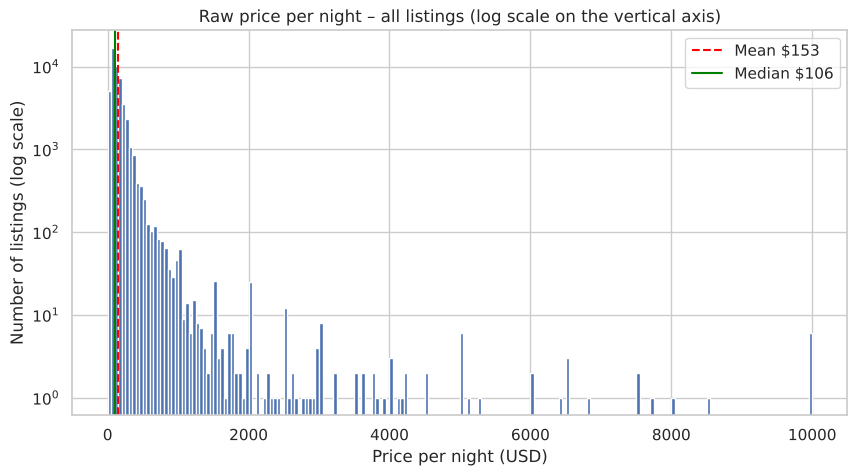

In [25]:
plt.hist(abnb["price"], bins=200, color="#4C72B0")
plt.yscale("log")   # log scale so the few very expensive listings are visible
plt.axvline(mean_p, color="red", linestyle="--", label=f"Mean ${mean_p:,.0f}")
plt.axvline(median_p, color="green", linestyle="-", label=f"Median ${median_p:,.0f}")
plt.title("Raw price per night – all listings (log scale on the vertical axis)")
plt.xlabel("Price per night (USD)")
plt.ylabel("Number of listings (log scale)")
plt.legend()
plt.show()

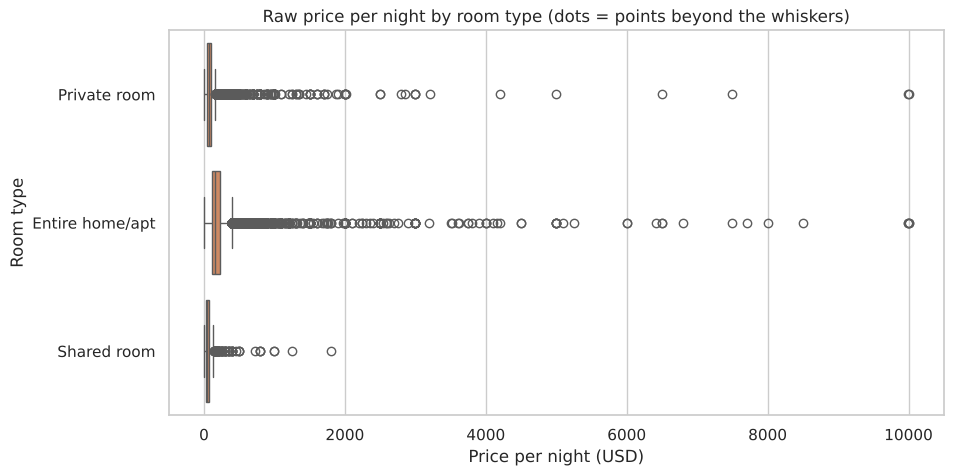

In [26]:
sns.boxplot(data=abnb, x="price", y="room_type", color="#DD8452")
plt.title("Raw price per night by room type (dots = points beyond the whiskers)")
plt.xlabel("Price per night (USD)")
plt.ylabel("Room type")
plt.show()

In [27]:
abnb.groupby("room_type")["price"].agg(["count", "mean", "median", "std", "max"]).round(2)

,count,mean,median,std,max
room_type,,,,,
Entire home/apt,25409,211.79,160.0,284.04,10000
Private room,22326,89.78,70.0,160.21,10000
Shared room,1160,70.13,45.0,101.73,1800


Each room type has a very different "normal" price: an entire home's median is about \$160 while a shared room's is about \$45. A \$300 shared room is suspicious, but a \$300 entire apartment is ordinary. This matters for choosing the final technique.

## 11. Step 1 – Remove impossible prices (\$0)

In [28]:
abnb_pos = abnb[abnb["price"] > 0].copy()
print(f"Removed {len(abnb) - len(abnb_pos)} listings priced at $0 -> {len(abnb_pos):,} listings remain")

Removed 11 listings priced at $0 -> 48,884 listings remain


## 12. Technique 1 – Mean ± 3 standard deviations (Z-score)

Based on the **mean** (central tendency) and **standard deviation** (dispersion). A price is an outlier when its Z-score $z = (x - \bar{x}) / s$ is above 3 in absolute value.

In [29]:
results_b = []   # we will collect every technique here

def record(name, lower, upper, data=abnb_pos):
    kept = data[(data["price"] >= lower) & (data["price"] <= upper)]
    results_b.append({"Technique": name,
                      "Lower limit ($)": round(lower, 2),
                      "Upper limit ($)": round(upper, 2),
                      "Listings removed": len(data) - len(kept),
                      "% removed": round(100 * (len(data) - len(kept)) / len(data), 2),
                      "Mean after ($)": round(kept["price"].mean(), 2),
                      "Median after ($)": round(kept["price"].median(), 2),
                      "Max after ($)": kept["price"].max()})
    return kept

m, s = abnb_pos["price"].mean(), abnb_pos["price"].std()
z_lower, z_upper = m - 3 * s, m + 3 * s
z_clean = record("Z-score (mean ± 3 SD)", z_lower, z_upper)
print(f"Mean ${m:,.2f}, SD ${s:,.2f} -> limits [{z_lower:,.2f}, {z_upper:,.2f}]")
print(f"Removed {len(abnb_pos) - len(z_clean)} listings; max price kept ${z_clean['price'].max():,}")

Mean $152.76, SD $240.17 -> limits [-567.76, 873.27]
Removed 388 listings; max price kept $860


The lower limit is **negative**, so it can never remove cheap outliers, and the upper limit (≈\$870) is very high. The problem is that the extreme prices themselves inflate the mean and the standard deviation – the method is "masked" by the outliers it is trying to find. Z-scores assume a roughly normal distribution, and this price distribution is far from normal.

## 13. Technique 2 – Interquartile range (IQR / Tukey's fences)

Based on the **quartiles** (the median family). Outliers are below $Q1 - 1.5 \times IQR$ or above $Q3 + 1.5 \times IQR$, where $IQR = Q3 - Q1$. Quartiles are not pulled by extreme values.

In [30]:
q1, q3 = abnb_pos["price"].quantile([0.25, 0.75])
iqr = q3 - q1
iqr_lower, iqr_upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
iqr_clean = record("IQR (1.5 × IQR, all listings)", iqr_lower, iqr_upper)
print(f"Q1 ${q1}, Q3 ${q3}, IQR ${iqr} -> limits [{iqr_lower}, {iqr_upper}]")
print(f"Removed {len(abnb_pos) - len(iqr_clean)} listings; max price kept ${iqr_clean['price'].max():,}")

Q1 $69.0, Q3 $175.0, IQR $106.0 -> limits [-90.0, 334.0]
Removed 2972 listings; max price kept $334


## 14. Technique 3 – Percentile trimming (1st to 99th percentile)

Keeps the middle 98% of prices. Simple and robust, but it **always** removes 2% of the data even if there were no real outliers, so the cut is arbitrary.

In [31]:
p_lower, p_upper = abnb_pos["price"].quantile([0.01, 0.99])
pct_clean = record("Percentiles (1st – 99th)", p_lower, p_upper)
print(f"1st percentile ${p_lower}, 99th percentile ${p_upper}")
print(f"Removed {len(abnb_pos) - len(pct_clean)} listings")

1st percentile $30.0, 99th percentile $799.0
Removed 867 listings


## 15. Technique 4 – Median ± 3 MAD (robust Z-score)

Same idea as the Z-score but built on the **median** and the **median absolute deviation (MAD)**, which ignore extreme values. The factor 1.4826 makes MAD comparable to a standard deviation.

In [32]:
med = abnb_pos["price"].median()
mad = 1.4826 * (abnb_pos["price"] - med).abs().median()
mad_lower, mad_upper = med - 3 * mad, med + 3 * mad
mad_clean = record("Median ± 3 MAD", mad_lower, mad_upper)
print(f"Median ${med}, scaled MAD ${mad:,.2f} -> limits [{mad_lower:,.2f}, {mad_upper:,.2f}]")
print(f"Removed {len(abnb_pos) - len(mad_clean)} listings")

Median $106.0, scaled MAD $68.20 -> limits [-98.60, 310.60]
Removed 3270 listings


## 16. Technique 5 – IQR per room type

The techniques above use **one** limit for every listing. But section 10 showed each room type has its own price level, so a single limit removes too many legitimate entire homes and too few overpriced shared rooms. Here the IQR fences are calculated **separately for each room type**.

In [33]:
group_limits = []
kept_parts = []
for room, grp in abnb_pos.groupby("room_type"):
    gq1, gq3 = grp["price"].quantile([0.25, 0.75])
    giqr = gq3 - gq1
    lo, hi = gq1 - 1.5 * giqr, gq3 + 1.5 * giqr
    kept = grp[(grp["price"] >= lo) & (grp["price"] <= hi)]
    kept_parts.append(kept)
    group_limits.append({"Room type": room, "Q1 ($)": gq1, "Q3 ($)": gq3,
                         "Lower limit ($)": lo, "Upper limit ($)": hi,
                         "Listings before": len(grp), "Listings removed": len(grp) - len(kept)})
room_iqr_clean = pd.concat(kept_parts).sort_index()
pd.DataFrame(group_limits)

,Room type,Q1 ($),Q3 ($),Lower limit ($),Upper limit ($),Listings before,Listings removed
0,Entire home/apt,120.0,229.0,-43.5,392.5,25407,1871
1,Private room,50.0,95.0,-17.5,162.5,22319,1290
2,Shared room,33.0,75.0,-30.0,138.0,1158,83


In [34]:
removed_room = len(abnb_pos) - len(room_iqr_clean)
results_b.append({"Technique": "IQR per room type",
                  "Lower limit ($)": "per group", "Upper limit ($)": "per group",
                  "Listings removed": removed_room,
                  "% removed": round(100 * removed_room / len(abnb_pos), 2),
                  "Mean after ($)": round(room_iqr_clean["price"].mean(), 2),
                  "Median after ($)": round(room_iqr_clean["price"].median(), 2),
                  "Max after ($)": room_iqr_clean["price"].max()})
print(f"Removed {removed_room} listings in total")

Removed 3244 listings in total


## 17. Comparing all techniques

In [35]:
comparison = pd.DataFrame(results_b).set_index("Technique")
comparison

,Lower limit ($),Upper limit ($),Listings removed,% removed,Mean after ($),Median after ($),Max after ($)
Technique,,,,,,,
Z-score (mean ± 3 SD),-567.76,873.27,388,0.79,138.78,105.0,860
"IQR (1.5 × IQR, all listings)",-90.0,334.0,2972,6.08,120.00,100.0,334
Percentiles (1st – 99th),30.0,799.0,867,1.77,138.50,105.0,799
Median ± 3 MAD,-98.6,310.6,3270,6.69,118.67,100.0,310
IQR per room type,per group,per group,3244,6.64,121.81,100.0,392


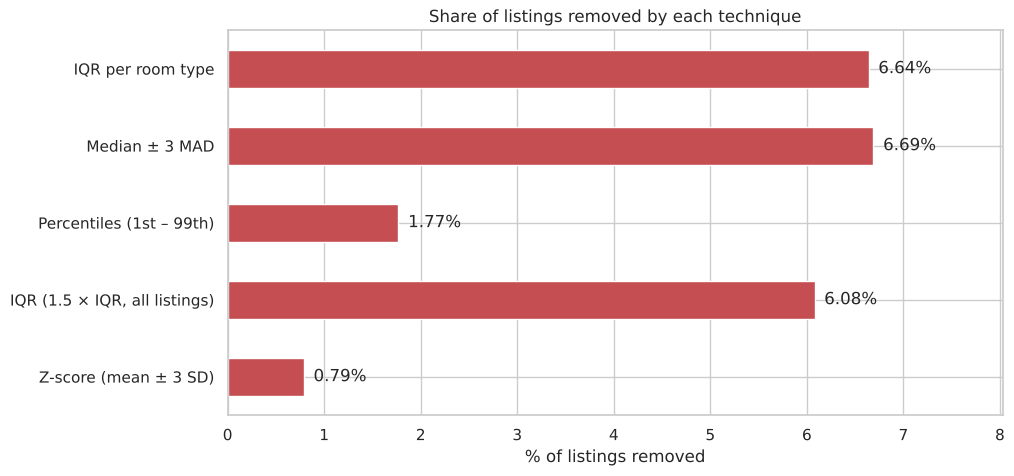

In [36]:
ax = comparison["% removed"].plot(kind="barh", color="#C44E52")
ax.set_title("Share of listings removed by each technique")
ax.set_xlabel("% of listings removed")
ax.set_ylabel("")
ax.set_xlim(0, comparison["% removed"].max() * 1.2)
for i, v in enumerate(comparison["% removed"]):
    ax.text(v + 0.1, i, f"{v}%", va="center")
plt.show()

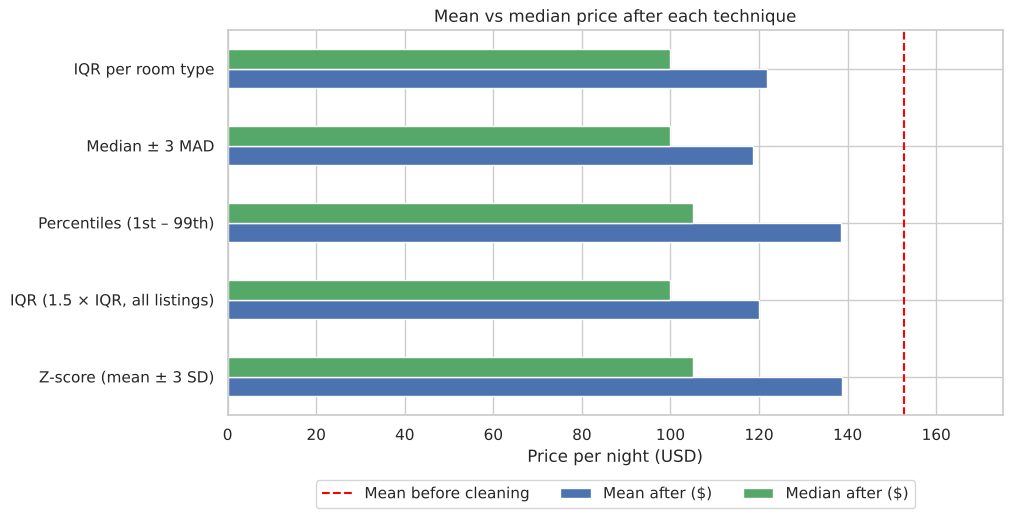

In [37]:
ax = comparison[["Mean after ($)", "Median after ($)"]].plot(kind="barh", color=["#4C72B0", "#55A868"])
ax.axvline(abnb_pos["price"].mean(), color="red", linestyle="--", label="Mean before cleaning")
ax.set_title("Mean vs median price after each technique")
ax.set_xlabel("Price per night (USD)")
ax.set_ylabel("")
ax.set_xlim(0, 175)
plt.legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=3)
plt.show()

**What the comparison shows:**

- **Z-score** removes the fewest listings (under 1%) and keeps prices up to \$860 – the mean and SD are themselves distorted by the outliers, so it is too permissive for skewed data.
- **Global IQR** and **median ± 3 MAD** are robust (they rely on quartiles/median). After cleaning, the gap between mean and median shrinks from about \$47 to about \$20 – a sign the extreme values that were pulling the mean up are gone.
- **Percentiles** work, but the 2% cut is a fixed choice, not a property of the data.
- **IQR per room type** uses the same robust rule but respects that each room type has its own normal price range.

## 18. Final choice and clean dataset

**Chosen technique:** remove the \$0 prices, then apply **IQR fences per room type**. It is robust to extreme values (quartiles, not mean), it is a standard and explainable rule, and it avoids treating a normal entire apartment as an outlier just because shared rooms are cheap.

In [38]:
abnb_clean = room_iqr_clean.copy()
print(f"Original listings:  {len(abnb):,}")
print(f"Clean listings:     {len(abnb_clean):,}")
print(f"Removed in total:   {len(abnb) - len(abnb_clean):,} "
      f"({100 * (len(abnb) - len(abnb_clean)) / len(abnb):.2f}%)")
abnb_clean.groupby("room_type")["price"].agg(["count", "mean", "median", "min", "max"]).round(2)

Original listings:  48,895
Clean listings:     45,640
Removed in total:   3,255 (6.66%)


,count,mean,median,min,max
room_type,,,,,
Entire home/apt,23536,168.77,150.0,10,392
Private room,21029,72.84,68.0,10,160
Shared room,1075,51.46,45.0,10,130


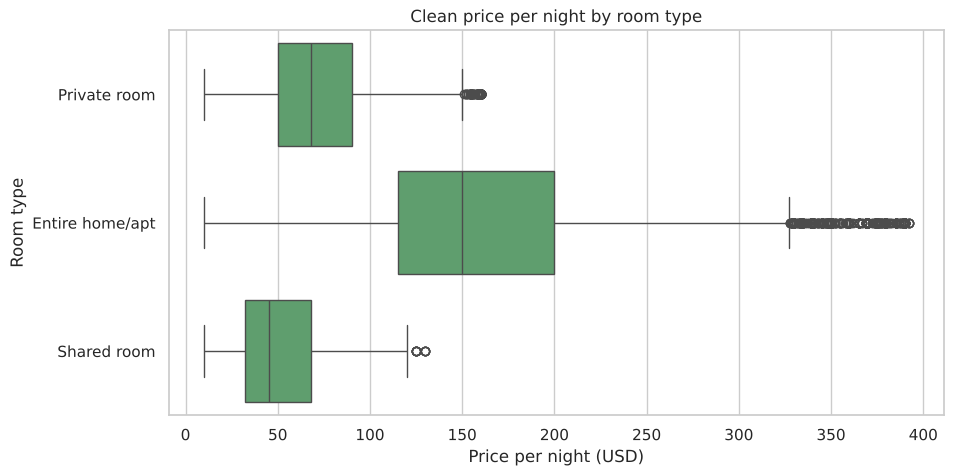

In [39]:
sns.boxplot(data=abnb_clean, x="price", y="room_type", color="#55A868")
plt.title("Clean price per night by room type")
plt.xlabel("Price per night (USD)")
plt.ylabel("Room type")
plt.show()

*Note:* the boxplot recalculates its whiskers on the **clean** data, so a few points can still appear beyond them. They are not outliers under the rule used to clean the data (based on the original quartiles of each room type) – the check at the end of this section confirms that 0 listings are outside those limits.

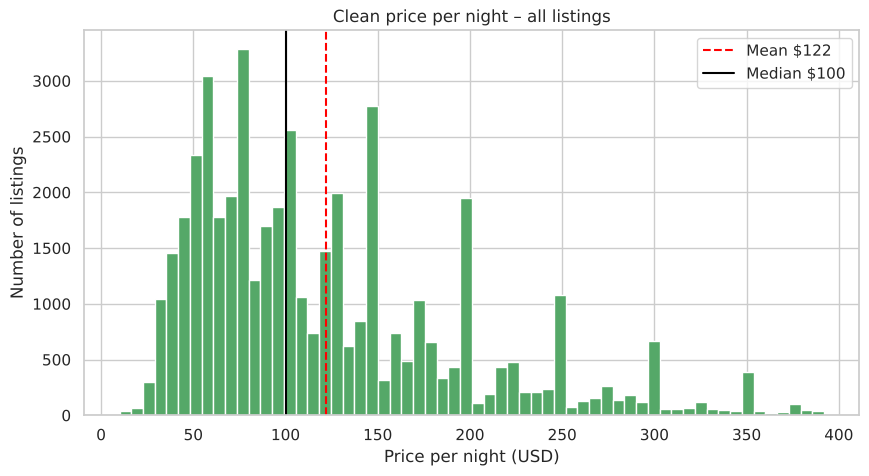

In [40]:
plt.hist(abnb_clean["price"], bins=60, color="#55A868")
plt.axvline(abnb_clean["price"].mean(), color="red", linestyle="--",
            label=f"Mean ${abnb_clean['price'].mean():,.0f}")
plt.axvline(abnb_clean["price"].median(), color="black",
            label=f"Median ${abnb_clean['price'].median():,.0f}")
plt.title("Clean price per night – all listings")
plt.xlabel("Price per night (USD)")
plt.ylabel("Number of listings")
plt.legend()
plt.show()

In [41]:
# Check: no remaining outliers inside any room type under the same rule
for room, grp in abnb_clean.groupby("room_type"):
    lim = next(g for g in group_limits if g["Room type"] == room)
    outside = ((grp["price"] < lim["Lower limit ($)"]) | (grp["price"] > lim["Upper limit ($)"])).sum()
    print(f"{room}: {outside} listings outside the limits")

abnb_clean.to_csv("AB_NYC_2019_clean_lab2.csv", index=False)
print("\nClean dataset saved as AB_NYC_2019_clean_lab2.csv")

Entire home/apt: 0 listings outside the limits
Private room: 0 listings outside the limits
Shared room: 0 listings outside the limits



Clean dataset saved as AB_NYC_2019_clean_lab2.csv


# 19. Conclusions

**Part A – Spam classification**

- Emails were turned into word counts and split 80/20 (stratified, duplicates removed first).
- With the full vocabulary, **MultinomialNB outperformed GaussianNB** (97% vs 95% test accuracy, and far fewer spam emails let through). With a reduced vocabulary GaussianNB can come close or edge ahead on one split, but 5-fold cross-validation confirms MultinomialNB as the best model overall. Word counts are discrete, non-negative and mostly zero, which is what the multinomial distribution describes; GaussianNB assumes bell-shaped continuous features.
- The trained MultinomialNB model predicted the test emails and new example emails correctly in most cases, and its most "spammy" words make intuitive sense.

**Part B – Airbnb price outliers**

- The raw price is extremely right-skewed (mean > median, SD > mean, max \$10,000, some \$0 listings).
- Mean-based rules (Z-score) fail on skewed data because the outliers inflate the mean and SD. Median/quartile-based rules (IQR, MAD, percentiles) are robust.
- The final clean dataset removes \$0 prices and applies **IQR fences per room type**, so each type of home is judged against its own normal price range. After cleaning, the gap between the mean and the median shrinks from about \$47 to about \$22, showing most of the distortion from extreme prices is gone.